In [1]:
import os, sys
sys.path.insert(0, '/home/edavenport/analysis/vel-assim-manuscript')
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import xgcm
from xmitgcm import open_mdsdataset
from open_tpose import tpose2012to2013

rho_0 = 1035.0   # kg/m³  (matches HeatFluxes examples)
Cp    = 3994.0   # J/(kg·K)

prefix    = ['diag_state', 'diag_heat_budget', 'diag_surf']
grid_dir  = '/data/SO6/TPOSE_diags/tpose6/grid_6/'
itPerFile = 72
offset    = 10
lon_slice = slice(140, 275)
lat_slice = slice(-17, 17)
moorings  = [(0, 190), (0, 220), (0, 250)]

## Load data

In [2]:
# ── TPOSE-Vel ─────────────────────────────────────────────────────────────
data_dir = '/data/SO3/edavenport/tpose6/diags/sep2012/run_iter14/'
num_diags = 30 + 31 + offset
intervals = range(itPerFile, itPerFile * num_diags, itPerFile)
ds_vel = open_mdsdataset(data_dir=data_dir, grid_dir=grid_dir, iters=intervals,
                         prefix=prefix, ref_date='2012-09-01', delta_t=1200)

for data_dir, num_d, ref in [
    ('/data/SO3/edavenport/tpose6/diags/nov2012/run_iter20/', 30+31+offset, '2012-11-01'),
    ('/data/SO3/edavenport/tpose6/diags/jan2013/run_iter14/', 31+28+offset, '2013-01-01'),
    ('/data/SO3/edavenport/tpose6/diags/mar2013/run_iter16/', 31+30+31+30,  '2013-03-01'),
]:
    ivals = range(itPerFile * offset, itPerFile * num_d, itPerFile)
    ds_vel = xr.concat([ds_vel,
        open_mdsdataset(data_dir=data_dir, grid_dir=grid_dir, iters=ivals,
                        prefix=prefix, ref_date=ref, delta_t=1200)], dim='time')

for c in ('XC', 'YC', 'Z', 'Zl', 'XG', 'YG'):
    if c in ds_vel.coords:
        ds_vel[c] = ds_vel[c].astype(float)
print('TPOSE-Vel:', ds_vel.dims)

TPOSE-Vel: FrozenMappingWarningOnValuesAccess({'time': 302, 'Z': 66, 'YC': 336, 'XC': 1128, 'XG': 1128, 'YG': 336, 'Zl': 66, 'Zp1': 67, 'Zu': 66})


In [3]:
# ── TPOSE-noVel ───────────────────────────────────────────────────────────
ds = tpose2012to2013(prefix)
for c in ('XC', 'YC', 'Z', 'Zl', 'XG', 'YG'):
    if c in ds.coords:
        ds[c] = ds[c].astype(float)
ds = ds.sel(time=slice('2012-09-01', '2013-06-30'))
print('TPOSE-noVel:', ds.dims)

mar2013/diags_daily/


may2013/diags_daily/


jul2013/diags_daily/


sep2013/diags_daily/


nov2013/diags_daily/


Days in 2012-2013: (should be 731)
731
TPOSE-noVel: FrozenMappingWarningOnValuesAccess({'time': 303, 'Z': 66, 'YC': 336, 'XC': 1128, 'XG': 1128, 'YG': 336, 'Zl': 66, 'Zp1': 67, 'Zu': 66})


## KPP + Diffusion vertical heat flux

Following `Heat_Flux_IntegrateUp.py` (`EqMixRemix_Processing/Python/TPOSE_2012/AllTendencies/HeatBudget/HeatFluxes/`):

1. KPP nonlocal tendency + total diffusion tendency (K/s)
2. Add non-solar surface flux (`TFLUX − oceQsw`) as a tendency at the surface level
3. Integrate **upward from the bottom** — at each depth, gives the upward vertical heat flux (K·m/s)
4. Multiply by ρ₀Cₚ → W/m²

Two map quantities extracted from the same profile:
- **At 50 m**: flux at the level nearest to Z = −50 m
- **0–250 m mean**: depth-mean over all levels with Z ≥ −250 m

Positive (red) = upward heat flux = heat into the upper ocean.

In [4]:
def kpp_flux_profile(ds_run):
    """
    Returns (flux_50m, flux_250m_mean) as 2D (YC, XC) DataArrays in W/m².
    flux_50m      : time-mean upward heat flux at Z ≈ -50 m
    flux_250m_mean: time-mean, depth-mean upward heat flux over Z 0 to -250 m
    Positive = upward = heat into the upper ocean.
    """
    grid = xgcm.Grid(ds_run, periodic=['X', 'Y'])
    vol  = ds_run.hFacC * ds_run.rA * ds_run.drF

    kpp_tend = grid.diff(ds_run.KPPg_TH, 'Z', boundary='fill', fill_value=0) / vol
    kpp_tend = kpp_tend.where(ds_run.hFacC > 0, 0)

    diff_x = -grid.diff(ds_run.DFxE_TH, 'X', boundary='extend') / vol
    diff_y = -grid.diff(ds_run.DFyE_TH, 'Y', boundary='extend') / vol
    diff_z = (grid.diff(ds_run.DFrE_TH, 'Z', boundary='fill', fill_value=0) +
              grid.diff(ds_run.DFrI_TH, 'Z', boundary='fill', fill_value=0)) / vol
    diff_tend = (diff_x + diff_y + diff_z).where(ds_run.hFacC > 0, 0)

    combined = (kpp_tend + diff_tend).compute()  # (time, Z, YC, XC)

    # Non-solar surface flux as tendency in top cell (K/s)
    hfac0 = ds_run.hFacC.isel(Z=0).astype(float).values
    drF0  = float(ds_run.drF.isel(Z=0))
    tflux_noSW = ((ds_run.TFLUX - ds_run.oceQsw).compute().values /
                  (rho_0 * Cp * hfac0[np.newaxis, :, :] * drF0))
    tflux_noSW = np.where(hfac0[np.newaxis, :, :] > 0, tflux_noSW, 0)

    # Integrate upward from bottom: flux_up[k] = Σ_{l=k}^{bottom} combined[l]*drF[l]
    combined_np = combined.values.copy()         # (time, Z, YC, XC)
    combined_np[:, 0, :, :] += tflux_noSW       # add surface flux to top level
    drF_np  = ds_run.drF.values                  # (Z,)
    flux_up = np.zeros_like(combined_np)
    for l in range(combined_np.shape[1] - 2, -1, -1):
        flux_up[:, l, :, :] = (flux_up[:, l+1, :, :] +
                                combined_np[:, l, :, :] * drF_np[l])
    flux_up *= rho_0 * Cp  # → W/m²

    flux_da = xr.DataArray(flux_up, dims=combined.dims, coords=combined.coords)

    # Extract the two map quantities
    z50_idx  = int(np.argmin(np.abs(ds_run.Z.values - (-50.0))))
    z_actual = float(ds_run.Z.isel(Z=z50_idx))
    flux_50m = flux_da.isel(Z=z50_idx).mean('time').compute()
    flux_50m.attrs['depth_label'] = f'Z ≈ {z_actual:.0f} m'

    flux_mean = flux_da.where(ds_run.Z >= -250).mean(['time', 'Z']).compute()

    return flux_50m, flux_mean

In [5]:
print('Computing noVel fluxes...')
kpp_noVel_50m, kpp_noVel_mean = kpp_flux_profile(ds)
print('Computing Vel fluxes...')
kpp_vel_50m,   kpp_vel_mean   = kpp_flux_profile(ds_vel)

kpp_diff_50m  = kpp_vel_50m  - kpp_noVel_50m
kpp_diff_mean = kpp_vel_mean - kpp_noVel_mean

depth_label = kpp_vel_50m.attrs.get('depth_label', '≈ -50 m')
print()
print(f'KPP+Diff flux at {depth_label} (W/m²):')
print(f'  noVel  p1/p99: {float(kpp_noVel_50m.quantile(0.01)):.1f} / {float(kpp_noVel_50m.quantile(0.99)):.1f}')
print(f'  Vel    p1/p99: {float(kpp_vel_50m.quantile(0.01)):.1f} / {float(kpp_vel_50m.quantile(0.99)):.1f}')
print()
print('KPP+Diff flux 0–250 m mean (W/m²):')
print(f'  noVel  p1/p99: {float(kpp_noVel_mean.quantile(0.01)):.1f} / {float(kpp_noVel_mean.quantile(0.99)):.1f}')
print(f'  Vel    p1/p99: {float(kpp_vel_mean.quantile(0.01)):.1f} / {float(kpp_vel_mean.quantile(0.99)):.1f}')

Computing noVel fluxes...


Computing Vel fluxes...



KPP+Diff flux at Z ≈ -48 m (W/m²):
  noVel  p1/p99: -70.7 / 97.4
  Vel    p1/p99: -70.7 / 97.4

KPP+Diff flux 0–250 m mean (W/m²):
  noVel  p1/p99: -79.8 / 50.1
  Vel    p1/p99: -80.3 / 49.3


## Figures

In [6]:
def make_figure(kpp_noVel, kpp_vel, kpp_diff, col3_title, outfile):
    """3×4 figure: UVEL section | UVEL map | WVEL map | KPP heat flux map."""
    fig, ax = plt.subplots(figsize=(26, 9), nrows=3, ncols=4, sharex=True)

    # ── Column 0: UVEL at 0°N, depth × lon section ──────────────────────────
    levels_u_sec = np.linspace(-1.0, 1.0, 150)
    for row, (label, dset) in enumerate([('TPOSE-noVel', ds), ('TPOSE-Vel', ds_vel),
                                         ('Difference',   None)]):
        if label == 'Difference':
            data = (ds_vel.UVEL.sel(YC=0, method='nearest').sel(XG=lon_slice).mean('time') -
                    ds.UVEL.sel(YC=0, method='nearest').sel(XG=lon_slice).mean('time'))
        else:
            data = dset.UVEL.sel(YC=0, method='nearest').sel(XG=lon_slice).mean('time')
        data.plot.contourf(ax=ax[row, 0], levels=levels_u_sec, cmap=cmo.balance,
                           cbar_kwargs={'label': '(m/s)'})
        for xv in [190, 220, 250]:
            ax[row, 0].axvline(xv, color='k', linestyle='--')
        ax[row, 0].set_ylim(-300, 0)
        ax[row, 0].set_title(f'{label}, avg U at 0°N')
        ax[row, 0].set_xlabel('' if row < 2 else 'Longitude')
        ax[row, 0].set_ylabel('Depth (m)')

    # ── Column 1: UVEL map, depth-mean 0–250 m ──────────────────────────────
    levels_u_map = np.linspace(-1.0, 1.0, 150)
    for row, (label, dset) in enumerate([('TPOSE-noVel', ds), ('TPOSE-Vel', ds_vel),
                                         ('Difference',   None)]):
        if label == 'Difference':
            data   = (ds_vel.UVEL.sel(YC=lat_slice, XG=lon_slice, Z=slice(0,-250)).mean(['time','Z']) -
                      ds.UVEL.sel(YC=lat_slice, XG=lon_slice, Z=slice(0,-250)).mean(['time','Z']))
            levels = np.linspace(-0.5, 0.5, 150)
        else:
            data   = dset.UVEL.sel(YC=lat_slice, XG=lon_slice, Z=slice(0,-250)).mean(['time','Z'])
            levels = levels_u_map
        data.plot.contourf(ax=ax[row, 1], levels=levels, cmap=cmo.balance,
                           cbar_kwargs={'label': '(m/s)'})
        for lat, lon in moorings:
            ax[row, 1].scatter(lon, lat, color='k', marker='x', s=75)
        ax[row, 1].set_title(f'{label}, avg U 0–250 m')
        ax[row, 1].set_xlabel('' if row < 2 else 'Longitude')
        ax[row, 1].set_ylabel('Latitude')

    # ── Column 2: WVEL map, depth-mean 0–250 m ──────────────────────────────
    levels_w = np.linspace(-0.000023, 0.000023, 51)
    for row, (label, dset) in enumerate([('TPOSE-noVel', ds), ('TPOSE-Vel', ds_vel),
                                         ('Difference',   None)]):
        if label == 'Difference':
            data   = (ds_vel.WVEL.sel(Zl=slice(0,-250)).mean(['time','Zl']) -
                      ds.WVEL.sel(Zl=slice(0,-250)).mean(['time','Zl']))
            levels = np.linspace(-0.000019, 0.000019, 51)
        else:
            data   = dset.WVEL.sel(Zl=slice(0,-250)).mean(['time','Zl'])
            levels = levels_w
        data.sel(XC=lon_slice, YC=lat_slice).plot.contourf(
            ax=ax[row, 2], levels=levels, cmap=cmo.balance,
            cbar_kwargs={'label': '(m/s)'})
        for lat, lon in moorings:
            ax[row, 2].scatter(lon, lat, color='k', marker='x', s=75)
        ax[row, 2].set_title(f'{label}, avg W 0–250 m')
        ax[row, 2].set_xlabel('' if row < 2 else 'Longitude')
        ax[row, 2].set_ylabel('Latitude')

    # ── Column 3: KPP+Diff heat flux ────────────────────────────────────────
    vmax = float(np.nanpercentile(
        np.concatenate([np.abs(kpp_noVel.values.ravel()),
                        np.abs(kpp_vel.values.ravel())]), 99))
    vmax_d = float(np.nanpercentile(np.abs(kpp_diff.values), 99))
    for row, (label, data) in enumerate([('TPOSE-noVel', kpp_noVel),
                                          ('TPOSE-Vel',   kpp_vel),
                                          ('Difference',  kpp_diff)]):
        levels = np.linspace(-vmax_d, vmax_d, 51) if label == 'Difference' else np.linspace(-vmax, vmax, 51)
        data.sel(XC=lon_slice, YC=lat_slice).plot.contourf(
            ax=ax[row, 3], levels=levels, cmap=cmo.balance,
            cbar_kwargs={'label': '(W/m²)'})
        for lat, lon in moorings:
            ax[row, 3].scatter(lon, lat, color='k', marker='x', s=75)
        ax[row, 3].set_title(f'{label}, {col3_title}')
        ax[row, 3].set_xlabel('' if row < 2 else 'Longitude')
        ax[row, 3].set_ylabel('Latitude')

    plt.tight_layout()
    fig.savefig(outfile, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved {outfile}')

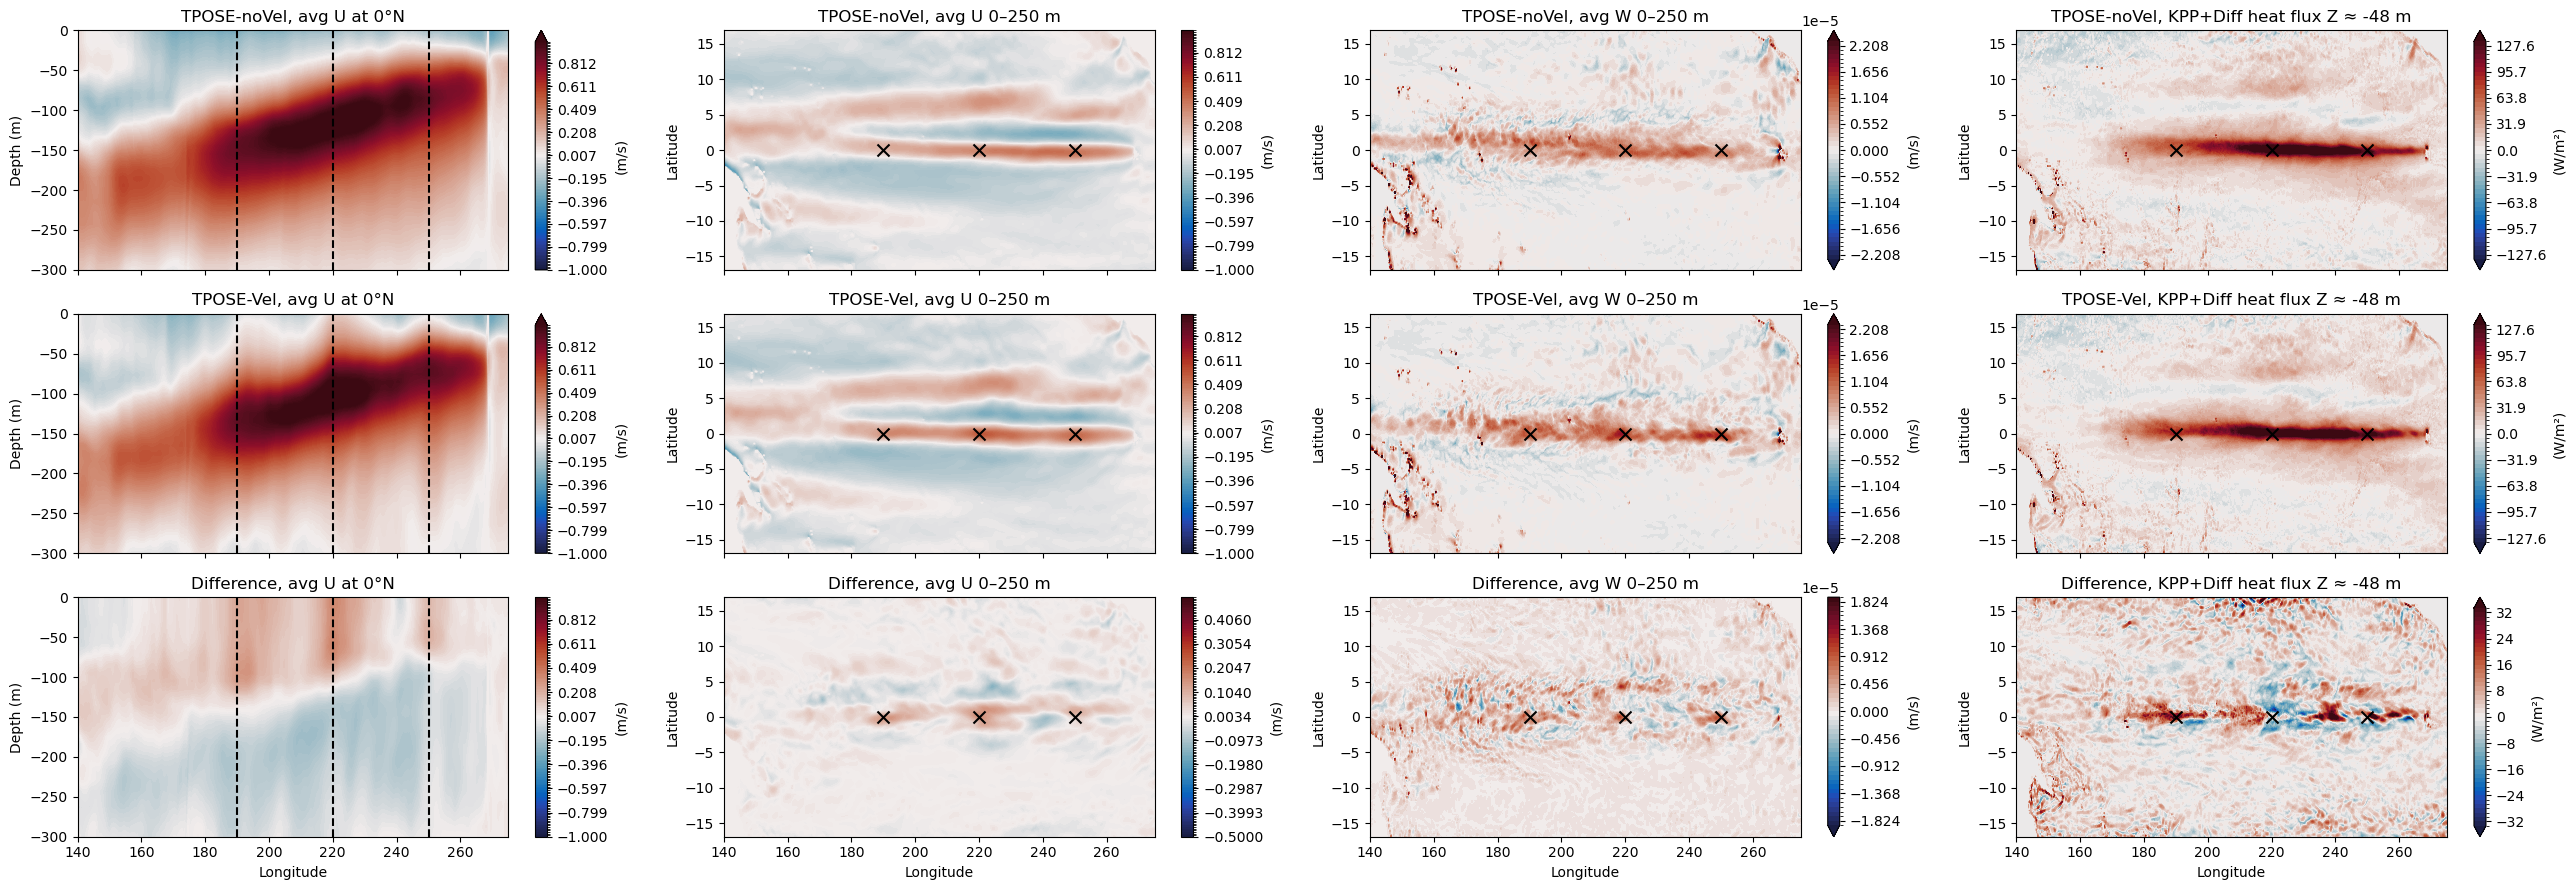

Saved wvel_uvel_kpp50m_difference.png


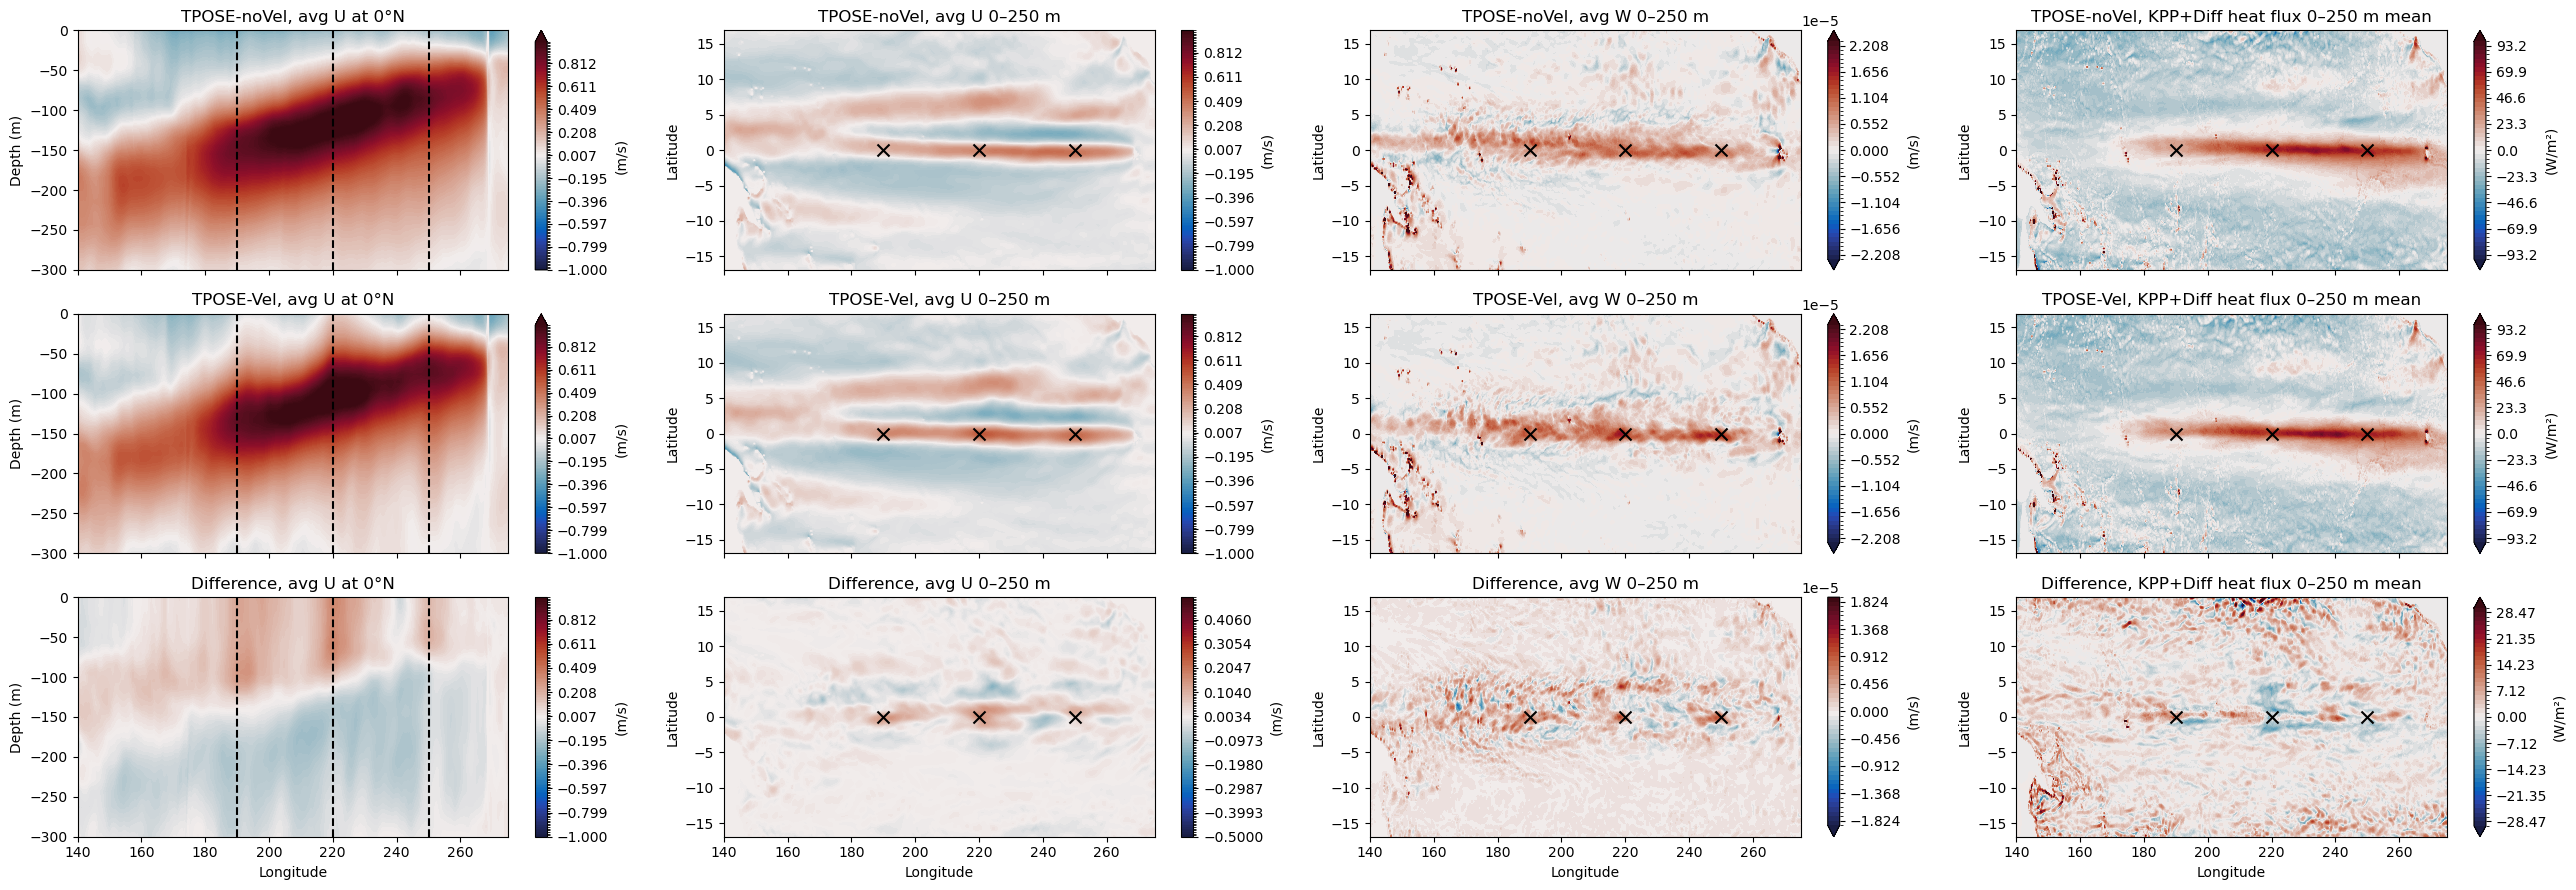

Saved wvel_uvel_kpp250m_difference.png


In [7]:
# Figure 1: KPP+Diff flux at Z ≈ 50 m
make_figure(
    kpp_noVel_50m, kpp_vel_50m, kpp_diff_50m,
    col3_title=f'KPP+Diff heat flux {depth_label}',
    outfile='wvel_uvel_kpp50m_difference.png',
)

# Figure 2: KPP+Diff flux depth-mean 0–250 m
make_figure(
    kpp_noVel_mean, kpp_vel_mean, kpp_diff_mean,
    col3_title='KPP+Diff heat flux 0–250 m mean',
    outfile='wvel_uvel_kpp250m_difference.png',
)

## Shortwave control adjustments

In [8]:
from mitgcm_assim.ctrls import load_controls_and_sensitivities

# TPOSE-Vel shortwave controls (xx_swdown)
ctrl_vel_segs = []
for data_dir, final_iter in [
    ('/data/SO3/edavenport/tpose6/diags/sep2012/run_iter14/', 14),
    ('/data/SO3/edavenport/tpose6/diags/nov2012/run_iter20/', 20),
    ('/data/SO3/edavenport/tpose6/diags/jan2013/run_iter14/', 14),
    ('/data/SO3/edavenport/tpose6/diags/mar2013/run_iter16/', 16),
]:
    ds_ctrl = load_controls_and_sensitivities(data_dir, grid_dir, final_iter)
    ctrl_vel_segs.append(ds_ctrl.xx_swdown)

# TPOSE-noVel shortwave controls (xx_swdown)
ctrl_noVel_segs = []
for data_dir, final_iter in [
    ('/data/SO6/TPOSE/tpose6/sep2012/ITER7/',  7),
    ('/data/SO6/TPOSE/tpose6/nov2012/ITER17/',  17),
    ('/data/SO6/TPOSE/tpose6/jan2013/ITER7/',  7),
    ('/data/SO6/TPOSE/tpose6/mar2013/ITER4/',  4),
]:
    ds_ctrl = load_controls_and_sensitivities(data_dir, grid_dir, final_iter)
    ctrl_noVel_segs.append(ds_ctrl.xx_swdown)

# Time-mean over all segments (concatenate then average)
sw_vel   = xr.concat(ctrl_vel_segs,   dim='time').mean('time').compute()
sw_noVel = xr.concat(ctrl_noVel_segs, dim='time').mean('time').compute()
# Cast coordinates to native endianness (controls loaded from big-endian MITgcm binary)
for _da in [sw_vel, sw_noVel]:
    for _c in ("XC", "YC"):
        if _c in _da.coords:
            _da[_c] = _da[_c].values.astype(float)
sw_diff  = sw_vel - sw_noVel
for _c in ("XC", "YC"):
    if _c in sw_diff.coords:
        sw_diff[_c] = sw_diff[_c].values.astype(float)

print('SW control adjustment (units of σ):')
print(f'  noVel  p1/p99: {float(sw_noVel.quantile(0.01)):.4f} / {float(sw_noVel.quantile(0.99)):.4f}')
print(f'  Vel    p1/p99: {float(sw_vel.quantile(0.01)):.4f} / {float(sw_vel.quantile(0.99)):.4f}')
print(f'  Diff   p1/p99: {float(sw_diff.quantile(0.01)):.4f} / {float(sw_diff.quantile(0.99)):.4f}')

SW control adjustment (units of σ):
  noVel  p1/p99: -0.0672 / 0.0609
  Vel    p1/p99: -0.0714 / 0.0813
  Diff   p1/p99: -0.0350 / 0.0663


In [9]:
def make_figure_5col(kpp_noVel, kpp_vel, kpp_diff, col4_title, sw_noVel, sw_vel, sw_diff, outfile):
    """3×5 figure: UVEL section | UVEL map | WVEL map | KPP heat flux | SW control."""
    fig, ax = plt.subplots(figsize=(32, 9), nrows=3, ncols=5, sharex=True)

    # ── Columns 0–3: identical to make_figure ────────────────────────────────
    levels_u_sec = np.linspace(-1.0, 1.0, 150)
    for row, (label, dset) in enumerate([('TPOSE-noVel', ds), ('TPOSE-Vel', ds_vel),
                                         ('Difference',   None)]):
        if label == 'Difference':
            data = (ds_vel.UVEL.sel(YC=0, method='nearest').sel(XG=lon_slice).mean('time') -
                    ds.UVEL.sel(YC=0, method='nearest').sel(XG=lon_slice).mean('time'))
        else:
            data = dset.UVEL.sel(YC=0, method='nearest').sel(XG=lon_slice).mean('time')
        data.plot.contourf(ax=ax[row, 0], levels=levels_u_sec, cmap=cmo.balance,
                           cbar_kwargs={'label': '(m/s)'})
        for xv in [190, 220, 250]:
            ax[row, 0].axvline(xv, color='k', linestyle='--')
        ax[row, 0].set_ylim(-300, 0)
        ax[row, 0].set_title(f'{label}, avg U at 0°N')
        ax[row, 0].set_xlabel('' if row < 2 else 'Longitude')
        ax[row, 0].set_ylabel('Depth (m)')

    levels_u_map = np.linspace(-1.0, 1.0, 150)
    for row, (label, dset) in enumerate([('TPOSE-noVel', ds), ('TPOSE-Vel', ds_vel),
                                         ('Difference',   None)]):
        if label == 'Difference':
            data   = (ds_vel.UVEL.sel(YC=lat_slice, XG=lon_slice, Z=slice(0,-250)).mean(['time','Z']) -
                      ds.UVEL.sel(YC=lat_slice, XG=lon_slice, Z=slice(0,-250)).mean(['time','Z']))
            levels = np.linspace(-0.5, 0.5, 150)
        else:
            data   = dset.UVEL.sel(YC=lat_slice, XG=lon_slice, Z=slice(0,-250)).mean(['time','Z'])
            levels = levels_u_map
        data.plot.contourf(ax=ax[row, 1], levels=levels, cmap=cmo.balance,
                           cbar_kwargs={'label': '(m/s)'})
        for lat, lon in moorings:
            ax[row, 1].scatter(lon, lat, color='k', marker='x', s=75)
        ax[row, 1].set_title(f'{label}, avg U 0–250 m')
        ax[row, 1].set_xlabel('' if row < 2 else 'Longitude')
        ax[row, 1].set_ylabel('Latitude')

    levels_w = np.linspace(-0.000023, 0.000023, 51)
    for row, (label, dset) in enumerate([('TPOSE-noVel', ds), ('TPOSE-Vel', ds_vel),
                                         ('Difference',   None)]):
        if label == 'Difference':
            data   = (ds_vel.WVEL.sel(Zl=slice(0,-250)).mean(['time','Zl']) -
                      ds.WVEL.sel(Zl=slice(0,-250)).mean(['time','Zl']))
            levels = np.linspace(-0.000019, 0.000019, 51)
        else:
            data   = dset.WVEL.sel(Zl=slice(0,-250)).mean(['time','Zl'])
            levels = levels_w
        data.sel(XC=lon_slice, YC=lat_slice).plot.contourf(
            ax=ax[row, 2], levels=levels, cmap=cmo.balance, cbar_kwargs={'label': '(m/s)'})
        for lat, lon in moorings:
            ax[row, 2].scatter(lon, lat, color='k', marker='x', s=75)
        ax[row, 2].set_title(f'{label}, avg W 0–250 m')
        ax[row, 2].set_xlabel('' if row < 2 else 'Longitude')
        ax[row, 2].set_ylabel('Latitude')

    vmax_kpp  = float(np.nanpercentile(np.concatenate([np.abs(kpp_noVel.values.ravel()),
                                                        np.abs(kpp_vel.values.ravel())]), 99))
    vmax_kpp_d = float(np.nanpercentile(np.abs(kpp_diff.values), 99))
    for row, (label, data) in enumerate([('TPOSE-noVel', kpp_noVel),
                                          ('TPOSE-Vel',   kpp_vel),
                                          ('Difference',  kpp_diff)]):
        levels = (np.linspace(-vmax_kpp_d, vmax_kpp_d, 51) if label == 'Difference'
                  else np.linspace(-vmax_kpp, vmax_kpp, 51))
        data.sel(XC=lon_slice, YC=lat_slice).plot.contourf(
            ax=ax[row, 3], levels=levels, cmap=cmo.balance, cbar_kwargs={'label': '(W/m²)'})
        for lat, lon in moorings:
            ax[row, 3].scatter(lon, lat, color='k', marker='x', s=75)
        ax[row, 3].set_title(f'{label}, {col4_title}')
        ax[row, 3].set_xlabel('' if row < 2 else 'Longitude')
        ax[row, 3].set_ylabel('Latitude')

    # ── Column 4: shortwave control adjustment ───────────────────────────────
    vmax_sw  = float(np.nanpercentile(np.concatenate([np.abs(sw_noVel.values.ravel()),
                                                       np.abs(sw_vel.values.ravel())]), 99))
    vmax_sw_d = float(np.nanpercentile(np.abs(sw_diff.values), 99))
    for row, (label, data) in enumerate([('TPOSE-noVel', sw_noVel),
                                          ('TPOSE-Vel',   sw_vel),
                                          ('Difference',  sw_diff)]):
        levels = (np.linspace(-vmax_sw_d, vmax_sw_d, 51) if label == 'Difference'
                  else np.linspace(-vmax_sw, vmax_sw, 51))
        data.sel(XC=lon_slice, YC=lat_slice).plot.contourf(
            ax=ax[row, 4], levels=levels, cmap=cmo.balance,
            cbar_kwargs={'label': '(units of σ)'})
        for lat, lon in moorings:
            ax[row, 4].scatter(lon, lat, color='k', marker='x', s=75)
        ax[row, 4].set_title(f'{label}, SW ctrl adj. (mean)')
        ax[row, 4].set_xlabel('' if row < 2 else 'Longitude')
        ax[row, 4].set_ylabel('Latitude')

    plt.tight_layout()
    fig.savefig(outfile, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved {outfile}')

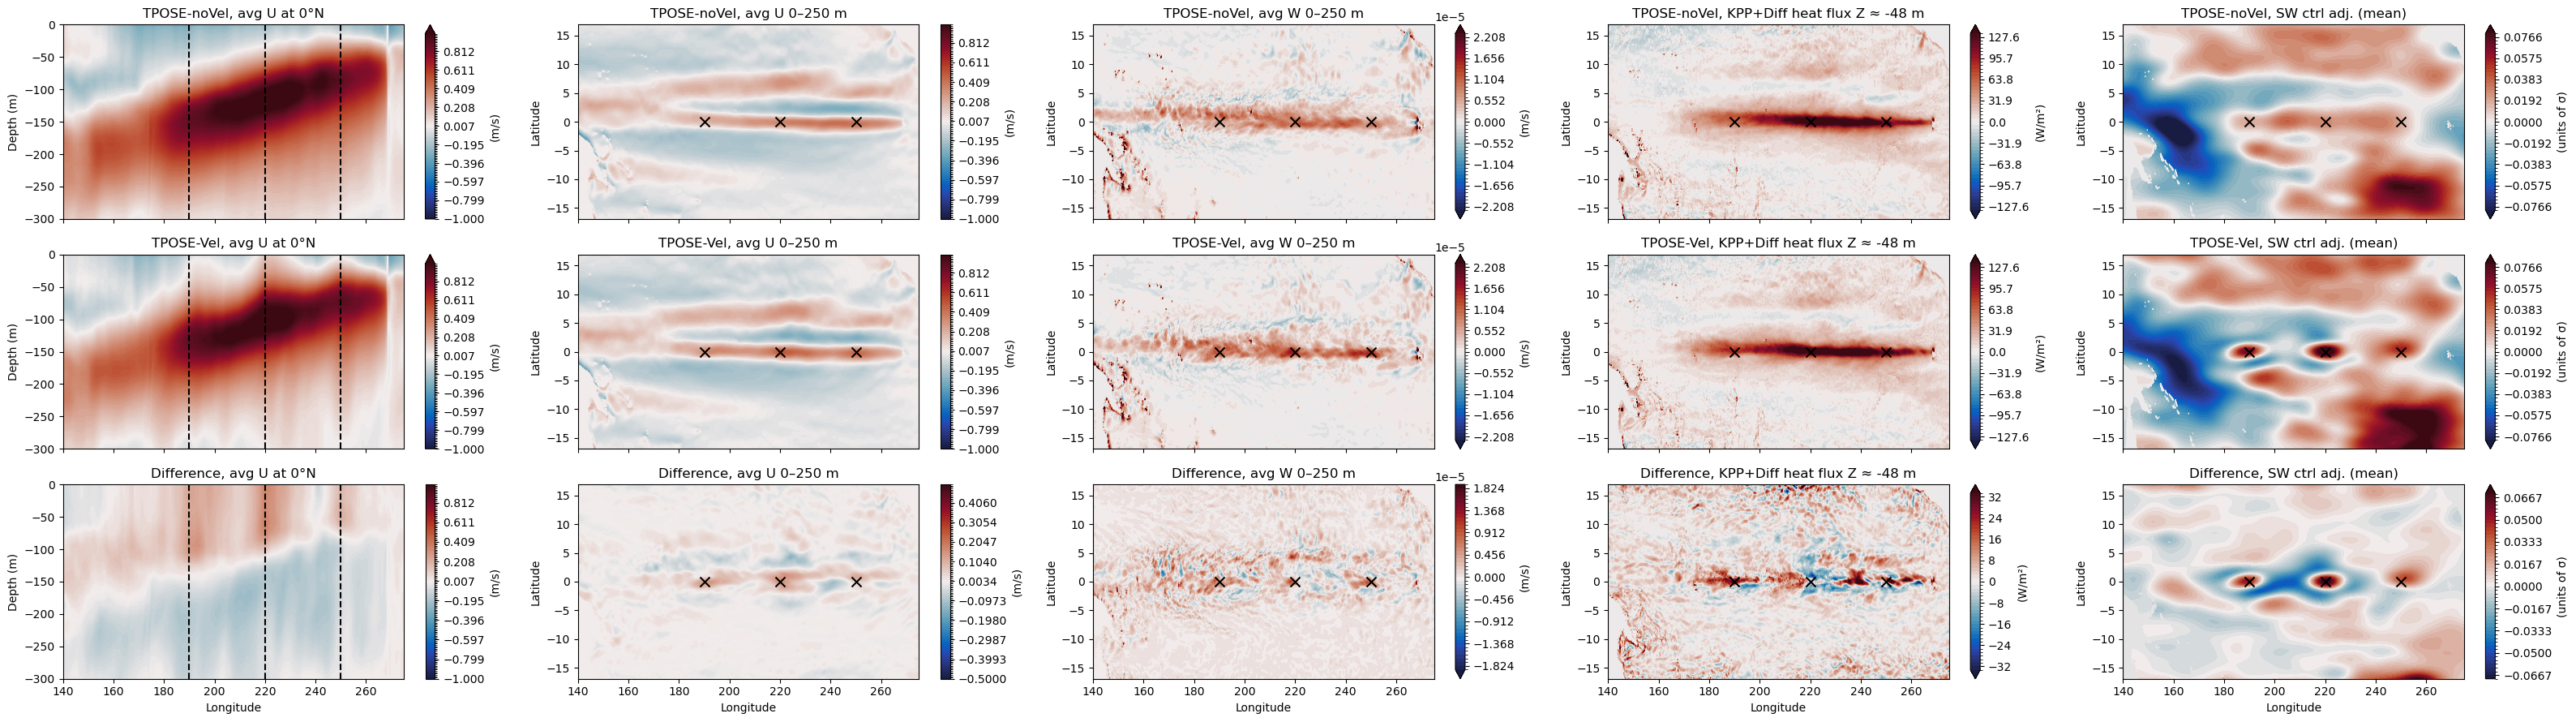

Saved wvel_uvel_kpp50m_sw_difference.png


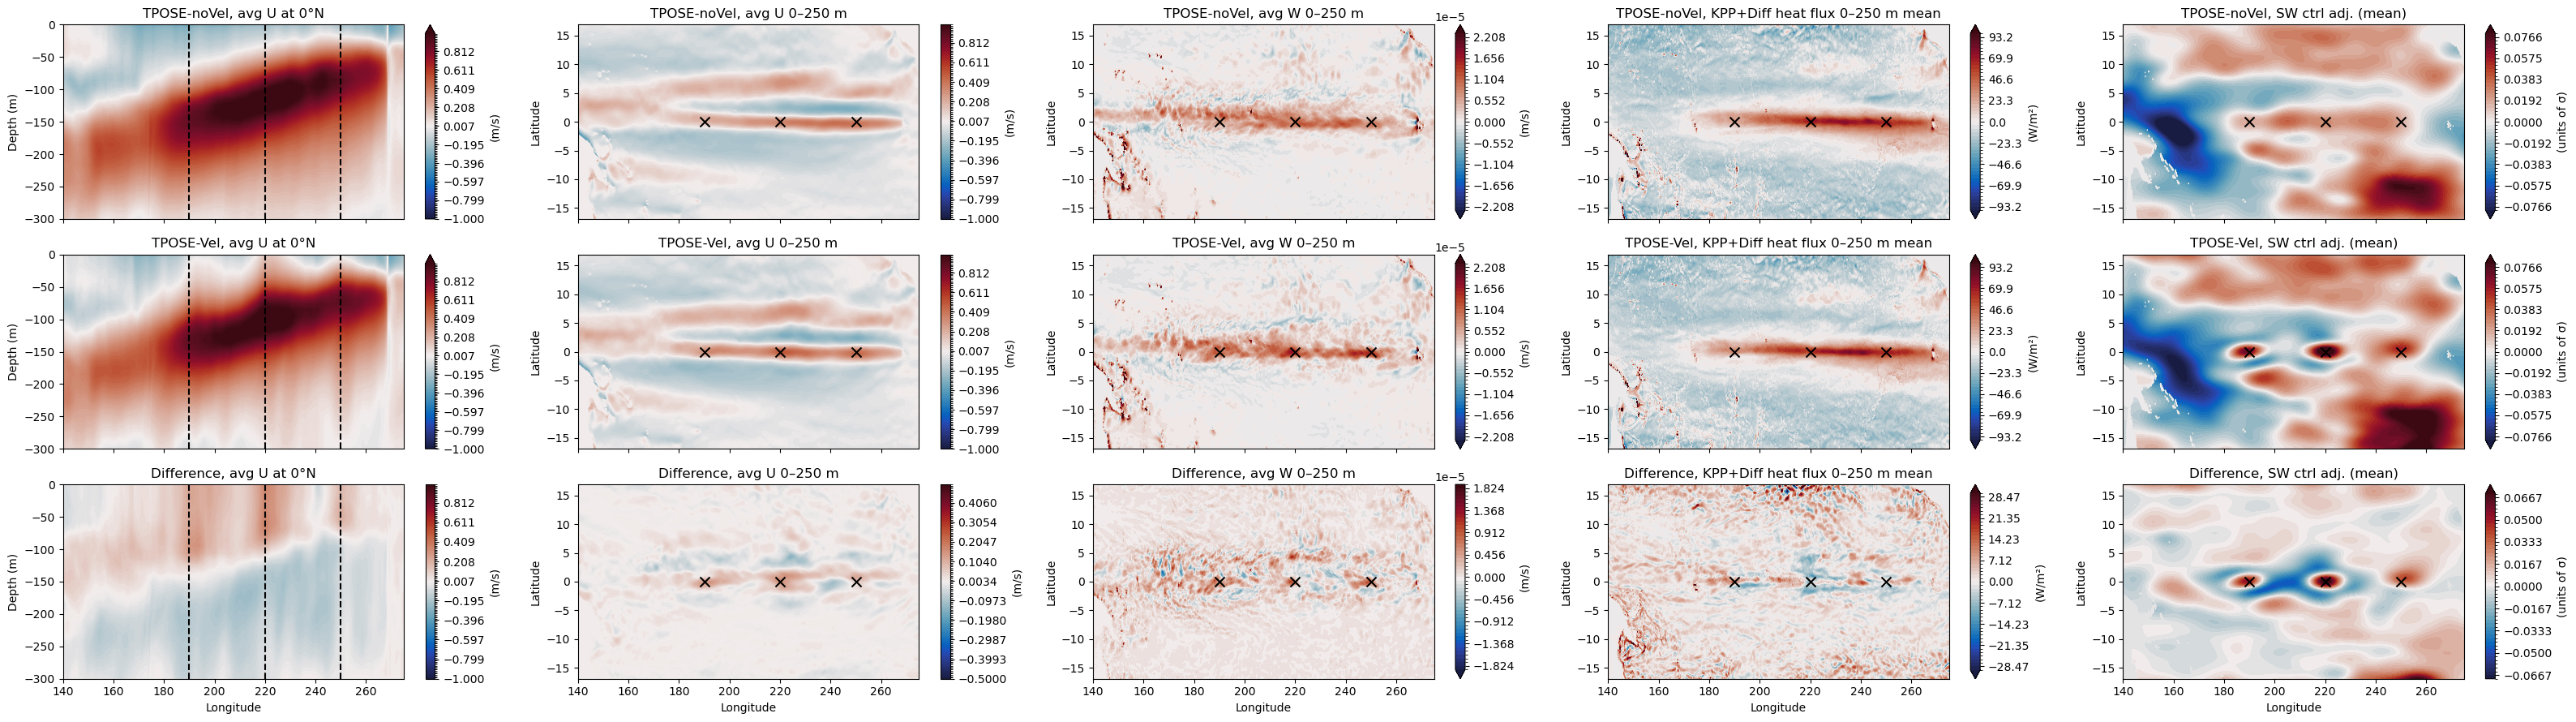

Saved wvel_uvel_kpp250m_sw_difference.png


In [10]:
# 5-column figure: KPP flux at Z ≈ 50 m + SW control
make_figure_5col(
    kpp_noVel_50m, kpp_vel_50m, kpp_diff_50m,
    col4_title=f'KPP+Diff heat flux {depth_label}',
    sw_noVel=sw_noVel, sw_vel=sw_vel, sw_diff=sw_diff,
    outfile='wvel_uvel_kpp50m_sw_difference.png',
)

# 5-column figure: KPP flux 0–250 m mean + SW control
make_figure_5col(
    kpp_noVel_mean, kpp_vel_mean, kpp_diff_mean,
    col4_title='KPP+Diff heat flux 0–250 m mean',
    sw_noVel=sw_noVel, sw_vel=sw_vel, sw_diff=sw_diff,
    outfile='wvel_uvel_kpp250m_sw_difference.png',
)

## Divergence (0–75 m) and new figures

In [11]:
def compute_div_75m(ds_run):
    """Horizontal velocity divergence (du/dx + dv/dy) averaged over 0–75 m, time-mean."""
    grid_r = xgcm.Grid(ds_run, periodic=['X','Y'])
    u_75m = ds_run.UVEL.where(ds_run.Z >= -75).mean(['Z','time']).compute()
    v_75m = ds_run.VVEL.where(ds_run.Z >= -75).mean(['Z','time']).compute()
    div = (grid_r.diff(u_75m, 'X', boundary='extend') / ds_run.dxF +
           grid_r.diff(v_75m, 'Y', boundary='extend') / ds_run.dyF)
    return div.compute()

print('Computing noVel divergence...')
div_noVel = compute_div_75m(ds)
print('Computing Vel divergence...')
div_vel   = compute_div_75m(ds_vel)
div_diff  = div_vel - div_noVel

print()
print('Divergence (1/s) — sanity check (~1e-6 s⁻¹ typical for tropical Pacific):')
print(f'  noVel  p1/p99: {float(div_noVel.quantile(0.01)):.2e} / {float(div_noVel.quantile(0.99)):.2e}')
print(f'  Vel    p1/p99: {float(div_vel.quantile(0.01)):.2e} / {float(div_vel.quantile(0.99)):.2e}')
print(f'  Diff   p1/p99: {float(div_diff.quantile(0.01)):.2e} / {float(div_diff.quantile(0.99)):.2e}')

Computing noVel divergence...


Computing Vel divergence...



Divergence (1/s) — sanity check (~1e-6 s⁻¹ typical for tropical Pacific):
  noVel  p1/p99: -2.39e-07 / 3.39e-07
  Vel    p1/p99: -2.37e-07 / 3.66e-07
  Diff   p1/p99: -1.63e-07 / 1.72e-07


In [12]:
def make_figure_5col_v2(col3_kpp, col3_title, sw_noVel, sw_vel, sw_diff, outfile):
    """
    3x5: UVEL section | UVEL 0-75m | VVEL 0-75m | divergence 0-75m | SW control.
    """
    fig, ax = plt.subplots(figsize=(32, 9), nrows=3, ncols=5, sharex=True)

    rows = [('TPOSE-noVel', ds, None),
            ('TPOSE-Vel',   ds_vel, None),
            ('Difference',  None, None)]

    # ── Col 0: UVEL at 0N section (unchanged) ────────────────────────────────
    for row, (label, dset, _) in enumerate(rows):
        if label == 'Difference':
            data = (ds_vel.UVEL.sel(YC=0, method='nearest').sel(XG=lon_slice).mean('time') -
                    ds.UVEL.sel(YC=0, method='nearest').sel(XG=lon_slice).mean('time'))
        else:
            data = dset.UVEL.sel(YC=0, method='nearest').sel(XG=lon_slice).mean('time')
        data.plot.contourf(ax=ax[row,0], levels=np.linspace(-1.0,1.0,150),
                           cmap=cmo.balance, cbar_kwargs={'label':'(m/s)'})
        for xv in [190,220,250]: ax[row,0].axvline(xv, color='k', linestyle='--')
        ax[row,0].set_ylim(-300, 0)
        ax[row,0].set_title(f'{label}, avg U at 0°N')
        ax[row,0].set_xlabel('' if row < 2 else 'Longitude')
        ax[row,0].set_ylabel('Depth (m)')

    # ── Col 1: UVEL map 0–75 m ───────────────────────────────────────────────
    vmax_u = float(np.nanpercentile(
        np.abs(np.concatenate([
            ds.UVEL.sel(YC=lat_slice, XG=lon_slice, Z=slice(0,-75)).mean(['time','Z']).values.ravel(),
            ds_vel.UVEL.sel(YC=lat_slice, XG=lon_slice, Z=slice(0,-75)).mean(['time','Z']).values.ravel(),
        ])), 99))
    for row, (label, dset, _) in enumerate(rows):
        if label == 'Difference':
            data = (ds_vel.UVEL.sel(YC=lat_slice, XG=lon_slice, Z=slice(0,-75)).mean(['time','Z']) -
                    ds.UVEL.sel(YC=lat_slice, XG=lon_slice, Z=slice(0,-75)).mean(['time','Z']))
            vmax_u_d = float(np.nanpercentile(np.abs(data.values), 99))
            levels = np.linspace(-vmax_u_d, vmax_u_d, 51)
        else:
            data = dset.UVEL.sel(YC=lat_slice, XG=lon_slice, Z=slice(0,-75)).mean(['time','Z'])
            levels = np.linspace(-vmax_u, vmax_u, 51)
        data.plot.contourf(ax=ax[row,1], levels=levels, cmap=cmo.balance,
                           cbar_kwargs={'label':'(m/s)'})
        for lat, lon in moorings: ax[row,1].scatter(lon, lat, color='k', marker='x', s=75)
        ax[row,1].set_title(f'{label}, avg U 0–75 m')
        ax[row,1].set_xlabel('' if row < 2 else 'Longitude')
        ax[row,1].set_ylabel('Latitude')

    # ── Col 2: VVEL map 0–75 m ───────────────────────────────────────────────
    vmax_v = float(np.nanpercentile(
        np.abs(np.concatenate([
            ds.VVEL.sel(YG=lat_slice, XC=lon_slice, Z=slice(0,-75)).mean(['time','Z']).values.ravel(),
            ds_vel.VVEL.sel(YG=lat_slice, XC=lon_slice, Z=slice(0,-75)).mean(['time','Z']).values.ravel(),
        ])), 99))
    for row, (label, dset, _) in enumerate(rows):
        if label == 'Difference':
            data = (ds_vel.VVEL.sel(YG=lat_slice, XC=lon_slice, Z=slice(0,-75)).mean(['time','Z']) -
                    ds.VVEL.sel(YG=lat_slice, XC=lon_slice, Z=slice(0,-75)).mean(['time','Z']))
            vmax_v_d = float(np.nanpercentile(np.abs(data.values), 99))
            levels = np.linspace(-vmax_v_d, vmax_v_d, 51)
        else:
            data = dset.VVEL.sel(YG=lat_slice, XC=lon_slice, Z=slice(0,-75)).mean(['time','Z'])
            levels = np.linspace(-vmax_v, vmax_v, 51)
        data.plot.contourf(ax=ax[row,2], levels=levels, cmap=cmo.balance,
                           cbar_kwargs={'label':'(m/s)'})
        for lat, lon in moorings: ax[row,2].scatter(lon, lat, color='k', marker='x', s=75)
        ax[row,2].set_title(f'{label}, avg V 0–75 m')
        ax[row,2].set_xlabel('' if row < 2 else 'Longitude')
        ax[row,2].set_ylabel('Latitude')

    # ── Col 3: Horizontal divergence 0–75 m ──────────────────────────────────
    vmax_div = float(np.nanpercentile(
        np.abs(np.concatenate([div_noVel.sel(XC=lon_slice, YC=lat_slice).values.ravel(),
                               div_vel.sel(XC=lon_slice, YC=lat_slice).values.ravel()])), 99))
    vmax_div_d = float(np.nanpercentile(
        np.abs(div_diff.sel(XC=lon_slice, YC=lat_slice).values), 99))
    for row, (label, _, data_div) in enumerate(
            [('TPOSE-noVel', None, div_noVel),
             ('TPOSE-Vel',   None, div_vel),
             ('Difference',  None, div_diff)]):
        levels = (np.linspace(-vmax_div_d, vmax_div_d, 51) if label == 'Difference'
                  else np.linspace(-vmax_div, vmax_div, 51))
        data_div.sel(XC=lon_slice, YC=lat_slice).plot.contourf(
            ax=ax[row,3], levels=levels, cmap=cmo.balance,
            cbar_kwargs={'label':'(s⁻¹)'})
        for lat, lon in moorings: ax[row,3].scatter(lon, lat, color='k', marker='x', s=75)
        ax[row,3].set_title(f'{label}, ∂u/∂x+∂v/∂y, 0–75 m')
        ax[row,3].set_xlabel('' if row < 2 else 'Longitude')
        ax[row,3].set_ylabel('Latitude')

    # ── Col 4: SW control adjustment ──────────────────────────────────────────
    vmax_sw  = float(np.nanpercentile(
        np.abs(np.concatenate([sw_noVel.sel(XC=lon_slice, YC=lat_slice).values.ravel(),
                               sw_vel.sel(XC=lon_slice, YC=lat_slice).values.ravel()])), 99))
    vmax_sw_d = float(np.nanpercentile(
        np.abs(sw_diff.sel(XC=lon_slice, YC=lat_slice).values), 99))
    for row, (label, data_sw) in enumerate([('TPOSE-noVel', sw_noVel),
                                             ('TPOSE-Vel',   sw_vel),
                                             ('Difference',  sw_diff)]):
        levels = (np.linspace(-vmax_sw_d, vmax_sw_d, 51) if label == 'Difference'
                  else np.linspace(-vmax_sw, vmax_sw, 51))
        data_sw.sel(XC=lon_slice, YC=lat_slice).plot.contourf(
            ax=ax[row,4], levels=levels, cmap=cmo.balance,
            cbar_kwargs={'label':'(units of σ)'})
        for lat, lon in moorings: ax[row,4].scatter(lon, lat, color='k', marker='x', s=75)
        ax[row,4].set_title(f'{label}, SW ctrl adj. (mean)')
        ax[row,4].set_xlabel('' if row < 2 else 'Longitude')
        ax[row,4].set_ylabel('Latitude')

    plt.tight_layout()
    fig.savefig(outfile, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved {outfile}')

In [13]:
def make_figure_3col(sw_noVel, sw_vel, sw_diff, outfile):
    """3x3: UVEL section | divergence 0-75m | SW control."""
    fig, ax = plt.subplots(figsize=(20, 9), nrows=3, ncols=3, sharex=True)

    # ── Col 0: UVEL at 0N section ─────────────────────────────────────────────
    for row, (label, dset) in enumerate([('TPOSE-noVel', ds), ('TPOSE-Vel', ds_vel),
                                          ('Difference',   None)]):
        if label == 'Difference':
            data = (ds_vel.UVEL.sel(YC=0, method='nearest').sel(XG=lon_slice).mean('time') -
                    ds.UVEL.sel(YC=0, method='nearest').sel(XG=lon_slice).mean('time'))
        else:
            data = dset.UVEL.sel(YC=0, method='nearest').sel(XG=lon_slice).mean('time')
        data.plot.contourf(ax=ax[row,0], levels=np.linspace(-1.0,1.0,150),
                           cmap=cmo.balance, cbar_kwargs={'label':'(m/s)'})
        for xv in [190,220,250]: ax[row,0].axvline(xv, color='k', linestyle='--')
        ax[row,0].set_ylim(-300, 0)
        ax[row,0].set_title(f'{label}, avg U at 0°N')
        ax[row,0].set_xlabel('' if row < 2 else 'Longitude')
        ax[row,0].set_ylabel('Depth (m)')

    # ── Col 1: Horizontal divergence 0–75 m ──────────────────────────────────
    vmax_div  = float(np.nanpercentile(
        np.abs(np.concatenate([div_noVel.sel(XC=lon_slice, YC=lat_slice).values.ravel(),
                               div_vel.sel(XC=lon_slice, YC=lat_slice).values.ravel()])), 99))
    vmax_div_d = float(np.nanpercentile(
        np.abs(div_diff.sel(XC=lon_slice, YC=lat_slice).values), 99))
    for row, (label, data_div) in enumerate([('TPOSE-noVel', div_noVel),
                                              ('TPOSE-Vel',   div_vel),
                                              ('Difference',  div_diff)]):
        levels = (np.linspace(-vmax_div_d, vmax_div_d, 51) if label == 'Difference'
                  else np.linspace(-vmax_div, vmax_div, 51))
        data_div.sel(XC=lon_slice, YC=lat_slice).plot.contourf(
            ax=ax[row,1], levels=levels, cmap=cmo.balance,
            cbar_kwargs={'label':'(s⁻¹)'})
        for lat, lon in moorings: ax[row,1].scatter(lon, lat, color='k', marker='x', s=75)
        ax[row,1].set_title(f'{label}, ∂u/∂x+∂v/∂y, 0–75 m')
        ax[row,1].set_xlabel('' if row < 2 else 'Longitude')
        ax[row,1].set_ylabel('Latitude')

    # ── Col 2: SW control adjustment ──────────────────────────────────────────
    vmax_sw  = float(np.nanpercentile(
        np.abs(np.concatenate([sw_noVel.sel(XC=lon_slice, YC=lat_slice).values.ravel(),
                               sw_vel.sel(XC=lon_slice, YC=lat_slice).values.ravel()])), 99))
    vmax_sw_d = float(np.nanpercentile(
        np.abs(sw_diff.sel(XC=lon_slice, YC=lat_slice).values), 99))
    for row, (label, data_sw) in enumerate([('TPOSE-noVel', sw_noVel),
                                             ('TPOSE-Vel',   sw_vel),
                                             ('Difference',  sw_diff)]):
        levels = (np.linspace(-vmax_sw_d, vmax_sw_d, 51) if label == 'Difference'
                  else np.linspace(-vmax_sw, vmax_sw, 51))
        data_sw.sel(XC=lon_slice, YC=lat_slice).plot.contourf(
            ax=ax[row,2], levels=levels, cmap=cmo.balance,
            cbar_kwargs={'label':'(units of σ)'})
        for lat, lon in moorings: ax[row,2].scatter(lon, lat, color='k', marker='x', s=75)
        ax[row,2].set_title(f'{label}, SW ctrl adj. (mean)')
        ax[row,2].set_xlabel('' if row < 2 else 'Longitude')
        ax[row,2].set_ylabel('Latitude')

    plt.tight_layout()
    fig.savefig(outfile, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved {outfile}')

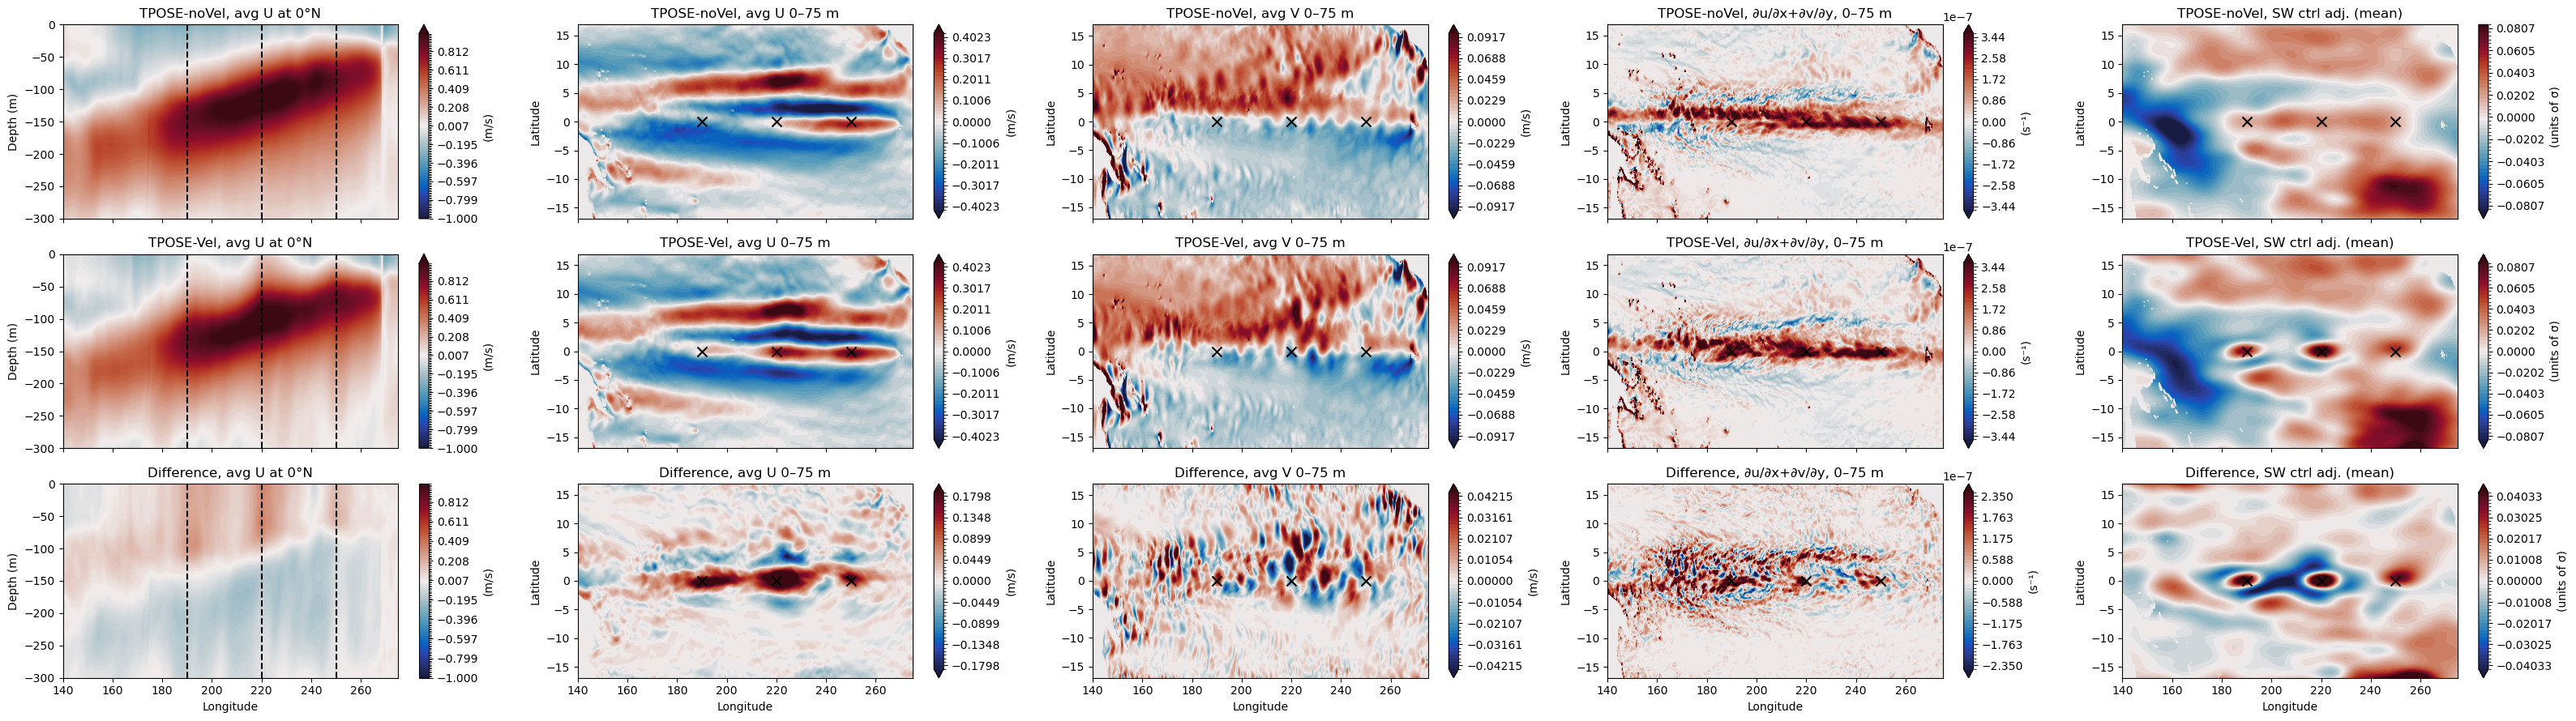

Saved wvel_uvel_div75m_sw_difference.png


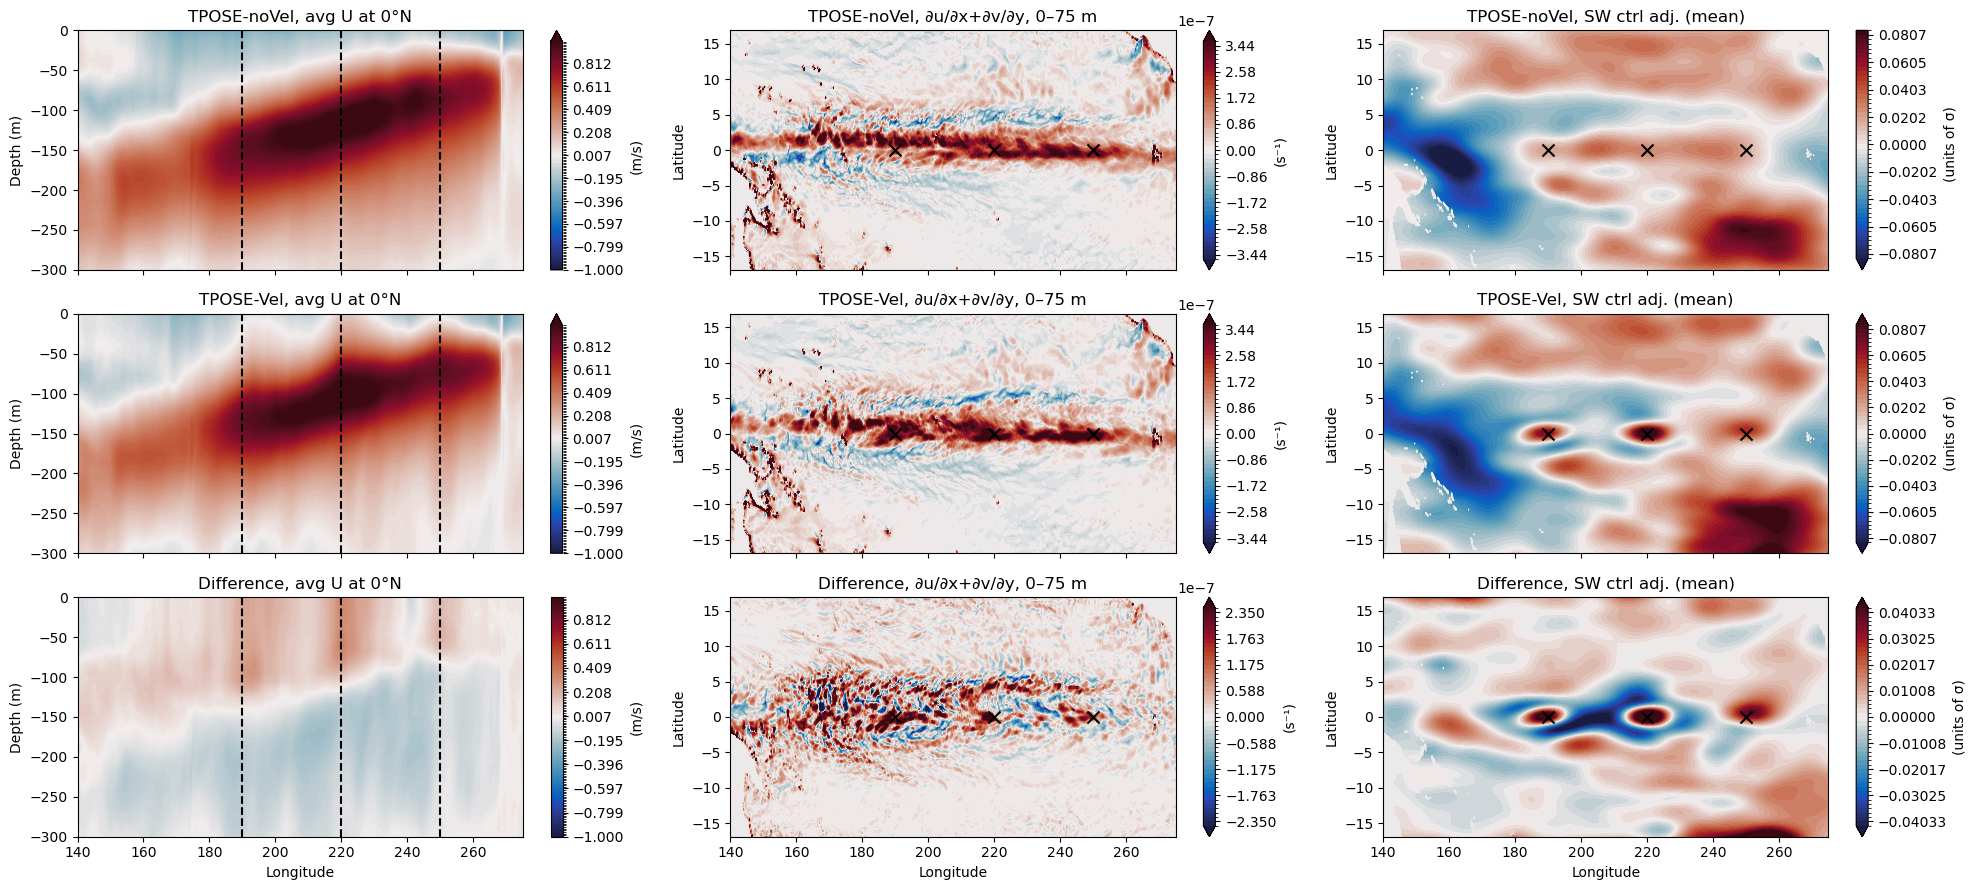

Saved uvel_div75m_sw_difference.png


In [14]:
make_figure_5col_v2(
    col3_kpp=None, col3_title=None,
    sw_noVel=sw_noVel, sw_vel=sw_vel, sw_diff=sw_diff,
    outfile='wvel_uvel_div75m_sw_difference.png',
)

make_figure_3col(
    sw_noVel=sw_noVel, sw_vel=sw_vel, sw_diff=sw_diff,
    outfile='uvel_div75m_sw_difference.png',
)